# 09 · AI3: catching fake-engagement influencers

**The problem, simply:** some influencers buy fake followers and likes. Prakriti pays them by
reach, so that money buys nothing. We cannot ask the influencer, and we have no list of who is fake.

**The approach:** an **Isolation Forest**, an unsupervised AI model. It never sees any
"fake/genuine" labels. It learns what normal creators look like and flags the ones that are easiest
to isolate as unusual. We compare it with a simple rule a marketing team might use today.

**Grading:** the true fake accounts are sealed in `truth.json`. The flags saved here are graded at
the final stage (precision@k and recall), so this notebook cannot be tuned to the answer.

Data: `influencers.csv`, 150 creators × 26 fortnights (weeks 35–86).

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from common import FULL, COLOR, INK, INK2, NEUTRAL, style, save, ROOT

style()
inf = pd.read_csv(FULL / "influencers.csv")
print(f"{inf.creator_id.nunique()} creators, {inf.fortnight.nunique()} fortnights, total spend ₹{inf.spend_lakh.sum():.1f} lakh")

150 creators, 26 fortnights, total spend ₹309.8 lakh


## 1. Describe each creator with six behaviour signals
Fake engagement leaves fingerprints: sudden follower jumps, many likes but few comments,
copy-paste comments, and an audience outside Prakriti's cities.

In [2]:
inf["engagement_rate"] = inf["likes"] / inf["followers"]
inf["comments_per_like"] = inf["comments"] / inf["likes"].clip(lower=1)
feat = inf.groupby(["creator_id", "tier"]).agg(
    engagement_rate=("engagement_rate", "median"),
    comments_per_like=("comments_per_like", "median"),
    max_follower_jump=("follower_growth", "max"),
    growth_volatility=("follower_growth", "std"),
    generic_comment_share=("generic_comment_share", "mean"),
    audience_city_match=("audience_city_match", "mean"),
    spend_lakh=("spend_lakh", "sum"),
).reset_index()
# engagement differs by creator size, so compare each creator with others of the same tier
feat["engagement_vs_tier"] = feat["engagement_rate"] / feat.groupby("tier")["engagement_rate"].transform("median")
FEATURES = ["engagement_vs_tier", "comments_per_like", "max_follower_jump", "growth_volatility",
            "generic_comment_share", "audience_city_match"]
feat[FEATURES].describe().round(3)

,engagement_vs_tier,comments_per_like,max_follower_jump,growth_volatility,generic_comment_share,audience_city_match
count,150.000,150.000,150.000,150.000,150.000,150.000
mean,1.063,0.043,0.039,0.011,0.155,0.529
std,0.299,0.007,0.081,0.027,0.126,0.082
min,0.850,0.009,0.015,0.003,0.093,0.194
25%,0.972,0.043,0.018,0.005,0.112,0.529
50%,1.000,0.045,0.020,0.005,0.122,0.548
75%,1.043,0.047,0.022,0.006,0.131,0.565
max,2.756,0.053,0.396,0.137,0.630,0.616


## 2. Baseline: a simple rule
Flag a creator whose engagement rate is more than 3 standard deviations from the median of their
tier (robust version: median absolute deviation).

In [3]:
def robust_z(s):
    mad = (s - s.median()).abs().median() * 1.4826
    return (s - s.median()) / mad
feat["rule_z"] = feat.groupby("tier")["engagement_rate"].transform(robust_z)
feat["flag_rule"] = feat["rule_z"].abs() > 3
print(f"Rule flags {feat.flag_rule.sum()} creators, ₹{feat.loc[feat.flag_rule, 'spend_lakh'].sum():.1f} lakh of spend")

Rule flags 11 creators, ₹10.4 lakh of spend


## 3. Isolation Forest at three settings
`contamination` is the model's guess of how much fraud exists. We do not know it, so we show
5%, 10% and 15% instead of picking one quietly.

In [4]:
X = RobustScaler().fit_transform(feat[FEATURES])
iso = IsolationForest(n_estimators=500, random_state=7).fit(X)
feat["anomaly_score"] = -iso.score_samples(X)               # higher = more unusual
for c in [0.05, 0.10, 0.15]:
    k = int(round(c * len(feat)))
    feat[f"flag_if_{int(c*100)}"] = feat["anomaly_score"].rank(ascending=False) <= k
summary = pd.DataFrame({
    m: {"creators flagged": int(feat[m].sum()), "spend flagged ₹ lakh": feat.loc[feat[m], "spend_lakh"].sum(),
        "share of influencer spend": feat.loc[feat[m], "spend_lakh"].sum() / feat.spend_lakh.sum()}
    for m in ["flag_rule", "flag_if_5", "flag_if_10", "flag_if_15"]}).T
summary.round(3)

,creators flagged,spend flagged ₹ lakh,share of influencer spend
flag_rule,11.0,10.434,0.034
flag_if_5,8.0,7.007,0.023
flag_if_10,15.0,18.602,0.060
flag_if_15,22.0,46.401,0.150


## 4. What makes a creator look suspicious?
Compare the creators the model ranks most unusual (top 10%) with everyone else.

In [5]:
top = feat["flag_if_10"]
prof = pd.DataFrame({"Flagged (top 10%)": feat.loc[top, FEATURES].median(), "Others": feat.loc[~top, FEATURES].median()})
prof["ratio"] = prof.iloc[:, 0] / prof.iloc[:, 1]
prof.round(3)

,Flagged (top 10%),Others,ratio
engagement_vs_tier,1.018,0.999,1.018
comments_per_like,0.041,0.045,0.918
max_follower_jump,0.355,0.020,17.934
growth_volatility,0.107,0.005,21.403
generic_comment_share,0.591,0.120,4.927
audience_city_match,0.263,0.550,0.478


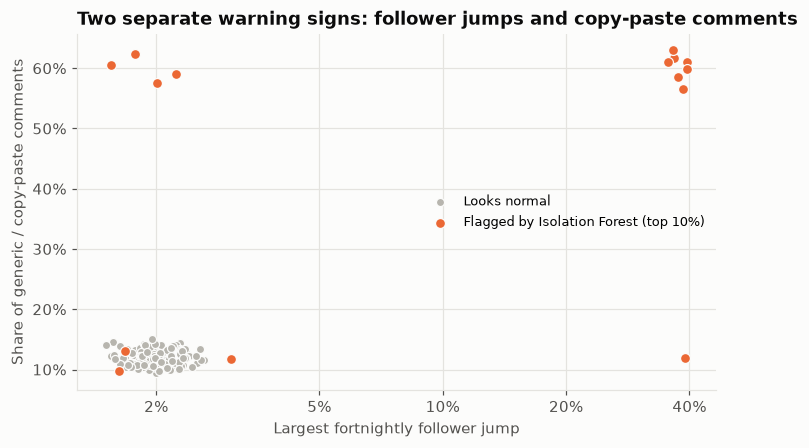

In [6]:
strength = np.log(prof["ratio"]).abs().sort_values(ascending=False)
fx, fy = "max_follower_jump", "generic_comment_share"     # two different kinds of warning sign
NICE = dict(engagement_vs_tier="Engagement vs tier median", comments_per_like="Comments per like",
            max_follower_jump="Largest fortnightly follower jump", growth_volatility="Follower-growth volatility",
            generic_comment_share="Share of generic / copy-paste comments", audience_city_match="Audience in Prakriti's cities")
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(feat.loc[~top, fx], feat.loc[~top, fy], s=28, color=NEUTRAL, label="Looks normal", edgecolor="#fcfcfb", linewidth=0.8)
ax.scatter(feat.loc[top, fx], feat.loc[top, fy], s=42, color=COLOR["qc_ads"], label="Flagged by Isolation Forest (top 10%)",
           edgecolor="#fcfcfb", linewidth=0.8)
ax.set_xlabel(NICE[fx]); ax.set_ylabel(NICE[fy])
ax.legend(frameon=False, fontsize=8.5)
ax.set_xscale("log")
ax.set_xticks([0.02, 0.05, 0.1, 0.2, 0.4], ["2%", "5%", "10%", "20%", "40%"]); ax.minorticks_off()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Two separate warning signs: follower jumps and copy-paste comments")
save(fig, "09_influencer_flags"); plt.show()

## 5. Agreement between the rule and the model

In [7]:
both = (feat.flag_rule & feat.flag_if_10).sum()
print(f"Rule flags {feat.flag_rule.sum()}, model (10%) flags {feat.flag_if_10.sum()}, both agree on {both}.")
print("The rule only looks at engagement rate; the model combines six signals, so it can catch accounts "
      "that inflate likes AND accounts that inflate followers or comments.")

Rule flags 11, model (10%) flags 15, both agree on 7.
The rule only looks at engagement rate; the model combines six signals, so it can catch accounts that inflate likes AND accounts that inflate followers or comments.


## 6. Save flags for grading (Stage F)

In [8]:
cols = ["creator_id", "tier", "anomaly_score", "rule_z", "flag_rule", "flag_if_5", "flag_if_10", "flag_if_15", "spend_lakh"]
feat[cols].sort_values("anomaly_score", ascending=False).to_csv(ROOT / "model" / "influencer_flags.csv", index=False)
print("Saved model/influencer_flags.csv (ranked by anomaly score)")

Saved model/influencer_flags.csv (ranked by anomaly score)


## 7. So what

In [9]:
s10 = summary.loc["flag_if_10"]
print("SO WHAT")
print(f"1. The model flags {int(s10['creators flagged'])} creators (10% setting) holding ₹{s10['spend flagged ₹ lakh']:.1f} lakh "
      f"({s10['share of influencer spend']:.0%}) of influencer spend for review before the next payment.")
print("2. Strongest warning signs (flagged vs others, median): " +
      "; ".join(f"{NICE[f].lower()} {prof.loc[f, 'ratio']:.1f}×" for f in strength.index[:3]) +
      ". All are signals a reviewer can check by hand.")
print("3. Governance: a flag triggers a human review, never an automatic cut-off (ASCI disclosure and fairness to creators).")
print("4. Accuracy is unknown until grading against the sealed fake list; the influencer ROI will then be recomputed without fake spend.")

SO WHAT
1. The model flags 15 creators (10% setting) holding ₹18.6 lakh (6%) of influencer spend for review before the next payment.
2. Strongest warning signs (flagged vs others, median): follower-growth volatility 21.4×; largest fortnightly follower jump 17.9×; share of generic / copy-paste comments 4.9×. All are signals a reviewer can check by hand.
3. Governance: a flag triggers a human review, never an automatic cut-off (ASCI disclosure and fairness to creators).
4. Accuracy is unknown until grading against the sealed fake list; the influencer ROI will then be recomputed without fake spend.
